# 03 · Hopf normal forms: onset, bistability, and switching
## Goal
Compare two-dimensional supercritical Hopf (Stuart–Landau) and stabilized subcritical Hopf dynamics before introducing recovery variables or coupling. This extends the theta/QIF study in `02_theta_qif_single_neuron.ipynb`.

**Questions:** How do equilibria and cycles change with the bifurcation parameter? What sets amplitude, frequency, and radial stability? When do initial conditions or pulses select different attractors? What does a reproducible hysteresis protocol actually measure?

**Scope:** deterministic, dimensionless, single-node mathematical experiments. No biological voltage/current/time calibration, spike-waveform claim, synapses, noise, or graph simulations. The global behavior of a quintic polynomial is studied as an explicitly chosen model; a local Hopf theorem alone does not establish that behavior for a biological neuron.

Outputs are embedded here and saved under `results/hopf/` relative to the execution directory. No data files or internet connection are needed to run the notebook.

## Setup
### Equations and conventions
Let $z=x+iy$, $q=|z|^2$, and $u=u_x+iu_y$. Use the common implementation
$$\dot z=[g(q)+i\Omega(q)]z+u(t).$$
| Model | $g(q)$ | $\Omega(q)$ | Default coefficients |
|---|---|---|---|
| Supercritical | $\mu-q$ | $\omega_0-cq$ | $\omega_0=2$, $c=0.5$ |
| Subcritical with quintic saturation | $\mu+\beta q-q^2$ | $\omega_0+c_3q$ | $\beta=1$, $\omega_0=2$, $c_3=0.5$ |

These match the catalog's conventions. All variables and time are dimensionless; angular frequency is in radians per model-time unit, and cyclic frequency $f=\Omega/(2\pi)$ is in inverse model time, **not Hz**. $\mu$ is a bifurcation parameter, not automatically injected current. $x$ is an observation coordinate, not calibrated membrane voltage.

With no forcing and $r>0$,
$$\dot r=r\,g(r^2),\qquad \dot\phi=\Omega(r^2).$$
The origin is best handled in Cartesian coordinates: phase is undefined there. Its eigenvalues are $\mu\pm i\omega_0$ in both models. A nonzero radial root is a periodic orbit only if $\Omega\ne0$; all cycle examples here have positive angular velocity.

### Reproducibility and assumptions
- We integrate the Cartesian ODE for phase portraits, waveforms, forcing, and numerical period benchmarks. Independent radial/log-radius equations are used for checks and efficient autonomous continuation.
- Adaptive DOP853 is the default; RK45 is used for a tolerance comparison. Event interpolation measures established-cycle periods, not sample-grid zero crossings.
- A positive $y=0$ crossing with $x>0$ counts a **cycle**, not a biological spike. Decaying subthreshold rotations are not classified as sustained firing.
- Input discontinuities are integrated in separate segments. Finite square pulses act in the positive $x$ direction; they are not changes to $\mu$.
- Initial conditions, forcing amplitudes, numerical tolerances, and continuation seed are explicit illustrative experimental choices. No randomness is used.
- To rerun, select a Python kernel with NumPy, SciPy, pandas, Matplotlib, IPython, and Jupyter. Versions are recorded below; there is no automatic installation.

In [1]:
from pathlib import Path
import json
import platform
import numpy as np
import pandas as pd
import scipy
from scipy.integrate import solve_ivp
from scipy.optimize import brentq
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

OUTPUT_DIR = Path('results') / 'hopf'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
OMEGA0, SHEAR, BETA = 2.0, 0.5, 1.0
COLORS = {'stable': '#2166AC', 'unstable': '#C56A18', 'neutral': '#444444'}
plt.rcParams.update({'figure.figsize': (9.2, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': 0.18,
                     'figure.dpi': 110, 'savefig.dpi': 160})
pd.set_option('display.precision', 7)
VERSIONS = {'python': platform.python_version(), 'numpy': np.__version__,
            'scipy': scipy.__version__, 'pandas': pd.__version__,
            'matplotlib': matplotlib.__version__}
print(VERSIONS)

def show_and_save(fig, stem):
    fig.savefig(OUTPUT_DIR / f'{stem}.png', bbox_inches='tight')
    plt.show()
    plt.close(fig)

def radial_gain(q, mu, model):
    if model == 'super':
        return mu-q
    if model == 'sub':
        return mu+BETA*q-q*q
    raise ValueError('model must be super or sub')

def angular_speed(q, model):
    if model not in ('super', 'sub'):
        raise ValueError('model must be super or sub')
    return OMEGA0 + (-SHEAR if model == 'super' else SHEAR)*q

def rhs(t, state, mu, model, force=(0., 0.)):
    x, y = state
    q = x*x+y*y
    gain, omega = radial_gain(q, mu, model), angular_speed(q, model)
    return [gain*x-omega*y+force[0], omega*x+gain*y+force[1]]

def positive_y_crossing(t, state):
    return state[1]
positive_y_crossing.direction = 1
positive_y_crossing.terminal = False

def integrate(mu, model, initial, duration, *, start=0., force=(0., 0.),
              method='DOP853', rtol=1e-9, atol=1e-11, max_step=0.15):
    sol = solve_ivp(lambda t, state: rhs(t, state, mu, model, force),
                    (start, start+duration), initial, method=method,
                    rtol=rtol, atol=atol, max_step=max_step,
                    dense_output=True, events=positive_y_crossing)
    if not sol.success:
        raise RuntimeError(sol.message)
    return sol

def cycle_radii(mu, model):
    """Return (radius, stability) for nonzero cycles; avoid fold endpoints."""
    if model == 'super':
        return [(np.sqrt(mu), 'stable')] if mu > 0 else []
    if model != 'sub':
        raise ValueError('Unknown model')
    disc = BETA**2+4*mu
    if disc < 0:
        return []
    if np.isclose(disc, 0., atol=1e-14, rtol=0):
        return [(np.sqrt(BETA/2), 'nonhyperbolic')]
    roots = [(BETA-np.sqrt(disc))/2, (BETA+np.sqrt(disc))/2]
    return [(np.sqrt(q), 'stable' if BETA-2*q < 0 else 'unstable')
            for q in roots if q > 0]

def radial_exponent(radius, mu, model):
    q = radius**2
    # At a nonzero radial root, g=0 and d(r*g)/dr = 2q*g'(q).
    return -2*q if model == 'super' else 2*q*(BETA-2*q)

{'python': '3.12.2', 'numpy': '2.2.6', 'scipy': '1.18.1', 'pandas': '3.0.6', 'matplotlib': '3.11.2'}


## Steps
### 1. Analytic branch structure and stability
**Supercritical:** for $\mu>0$, $r_s=\sqrt\mu$, radial exponent $\lambda_r=-2\mu$, and $f_s=(\omega_0-c\mu)/(2\pi)$ when this frequency is positive. The origin is stable for $\mu<0$, unstable for $\mu>0$. At $\mu=0$, $\dot r=-r^3$ gives algebraic decay: $r(t)=r_0/\sqrt{1+2r_0^2t}$. Oscillation amplitude approaches zero at onset while cycle frequency approaches $\omega_0/(2\pi)$.

**Subcritical, stabilized:** setting $q=r^2$ gives
$$q_\pm=\frac{\beta\pm\sqrt{\beta^2+4\mu}}2,\qquad
\lambda_r(q_\pm)=2q_\pm(\beta-2q_\pm).$$
For $-\beta^2/4<\mu<0$, $r_- =\sqrt{q_-}$ is an unstable cycle separating the basins of stable rest and the stable outer cycle $r_+=\sqrt{q_+}$. The cycle fold is at $\mu_F=-\beta^2/4=-0.25$, $r_F=\sqrt{\beta/2}$. At the fold the radial exponent is zero, so hyperbolic stability tests do not apply. For $\mu>0$, the origin is unstable and only the positive outer radial root remains. At $\mu=0$ the cubic term repels small nonzero radii despite zero real linear eigenvalues.

On a cycle, the tangential Floquet exponent is zero (phase neutrality); radial stability concerns the other exponent. Its multiplier is $\exp(\lambda_r T)$.

**Local versus global:** the unstable small cycle shrinking into the origin is the local subcritical Hopf branch. The stable outer cycle, its fold, the basin boundary, and hysteresis are properties of the specified quintic extension; they do not follow from the cubic local normal form alone.

,model,mu,object,radius,stability,radial_exponent,cycle_frequency
0,super,-0.1,origin,0.0000000,stable,NaN,NaN
1,super,0.1,origin,0.0000000,unstable,NaN,NaN
2,super,0.1,cycle,0.3162278,stable,-0.2000000,0.3103521
3,sub,-0.1,origin,0.0000000,stable,NaN,NaN
4,sub,-0.1,cycle,0.3357107,unstable,0.1745967,0.3272784
5,sub,-0.1,cycle,0.9419651,stable,-1.3745967,0.3889188
6,sub,0.1,origin,0.0000000,unstable,NaN,NaN
7,sub,0.1,cycle,1.0448004,stable,-2.5832160,0.4051773


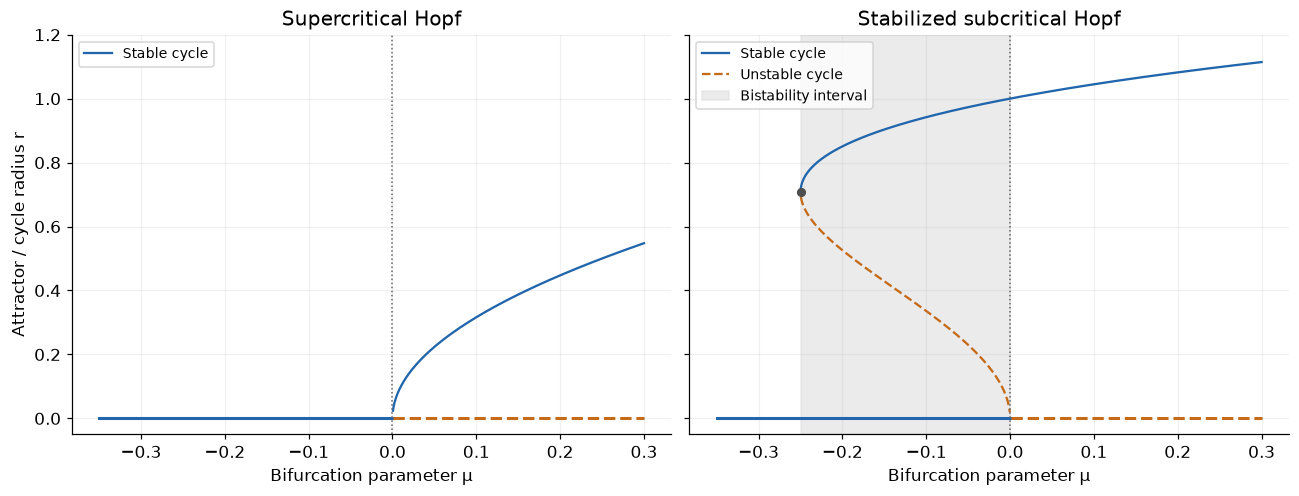

In [3]:
MU_FOLD = -BETA**2/4
MU_BISTABLE = -0.1
r_inner, r_outer = [r for r, stability in cycle_radii(MU_BISTABLE, 'sub')]
branch_rows = []
for model, mu in [('super', -0.1), ('super', 0.1), ('sub', -0.1), ('sub', 0.1)]:
    branch_rows.append({'model': model, 'mu': mu, 'object': 'origin',
                        'radius': 0., 'stability': 'stable' if mu < 0 else 'unstable',
                        'radial_exponent': np.nan, 'cycle_frequency': np.nan})
    for radius, stability in cycle_radii(mu, model):
        branch_rows.append({'model': model, 'mu': mu, 'object': 'cycle',
                            'radius': radius, 'stability': stability,
                            'radial_exponent': radial_exponent(radius, mu, model),
                            'cycle_frequency': angular_speed(radius**2, model)/(2*np.pi)})
branch_table = pd.DataFrame(branch_rows)
branch_table.to_csv(OUTPUT_DIR/'analytic_branches.csv', index=False)
display(branch_table)

fig, axes = plt.subplots(1, 2, figsize=(11.7, 4.4), sharey=True, layout='constrained')
mu_grid = np.linspace(-0.35, 0.3, 700)
for ax, model, title in zip(axes, ['super', 'sub'], ['Supercritical Hopf', 'Stabilized subcritical Hopf']):
    ax.plot(mu_grid[mu_grid < 0], np.zeros(sum(mu_grid < 0)),
             color=COLORS['stable'], linewidth=2)
    ax.plot(mu_grid[mu_grid >= 0], np.zeros(sum(mu_grid >= 0)), '--',
             color=COLORS['unstable'], linewidth=2)
    for stability, linestyle in [('stable', '-'), ('unstable', '--')]:
        vals = []
        for mu in mu_grid:
            found = [r for r, s in cycle_radii(mu, model) if s == stability]
            vals.append(found[0] if found else np.nan)
        if np.isfinite(vals).any():
            ax.plot(mu_grid, vals, linestyle, color=COLORS[stability],
                     label=f'{stability.capitalize()} cycle')
    ax.axvline(0, color='0.4', linestyle=':', linewidth=1)
    if model == 'sub':
        ax.axvspan(MU_FOLD, 0, color='0.85', alpha=0.5, label='Bistability interval')
        ax.plot(MU_FOLD, np.sqrt(BETA/2), 'o', color='0.3', markersize=5)
    ax.set(xlabel='Bifurcation parameter μ', title=title, ylim=(-0.05, 1.2))
    ax.legend(fontsize=9, loc='upper left')
axes[0].set_ylabel('Attractor / cycle radius r')
show_and_save(fig, '01_amplitude_branches')

**Interpretation:** solid/dashed curves denote stable/unstable objects; the zero-radius line denotes the equilibrium. The shaded interval contains two stable attractors and a separating unstable cycle. Numerical trajectories cannot trace an unstable cycle reliably without special initialization or continuation; its branch here is analytic.

### 2. Phase portraits and time-domain behavior
Use $\mu=\pm0.1$ and trajectories initialized on the positive $x$ axis. In the bistable subcritical panel, $0.6r_-$ and $1.1r_-$ start on opposite sides of the unstable cycle; a third trajectory starts outside the stable outer cycle. Quiver arrows show normalized direction only, not speed. Axis limits and aspect ratio are shared.

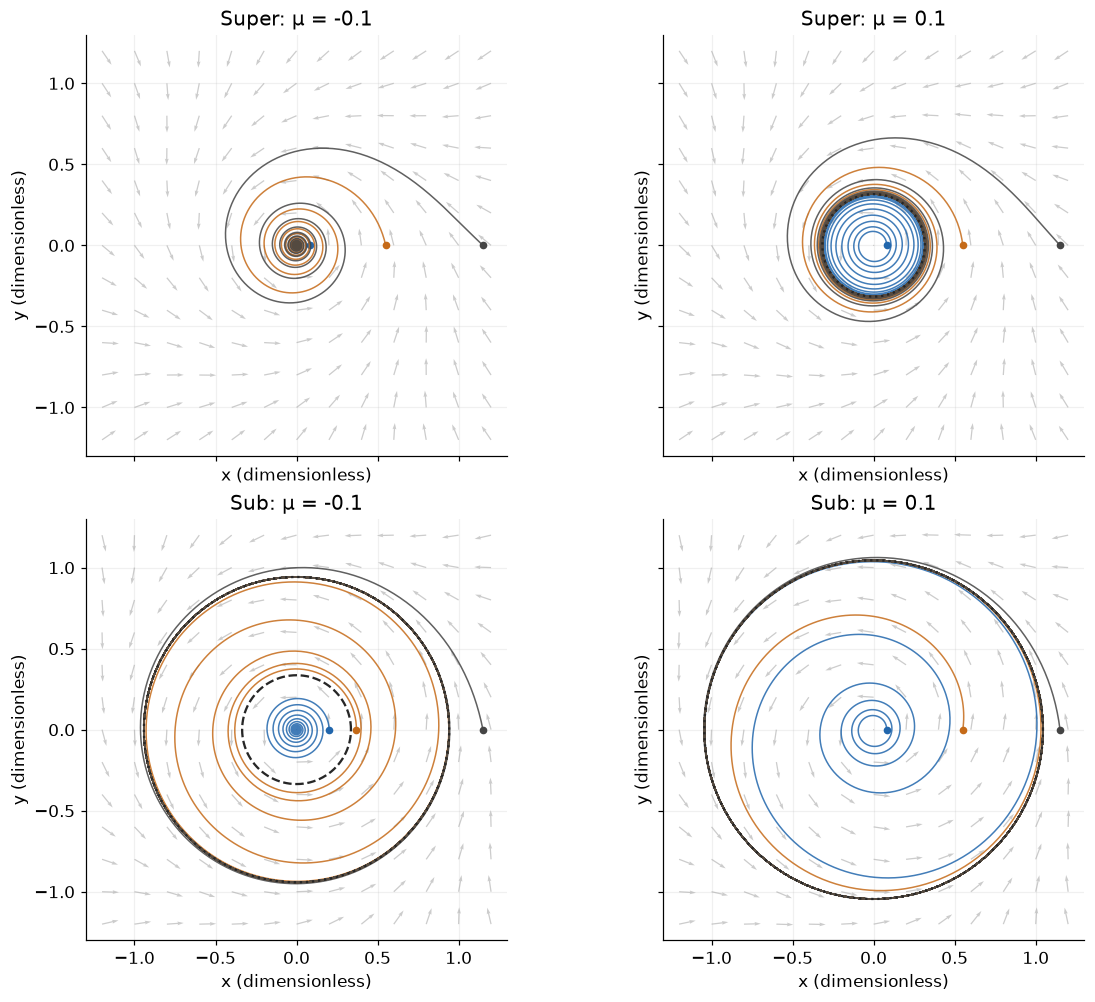

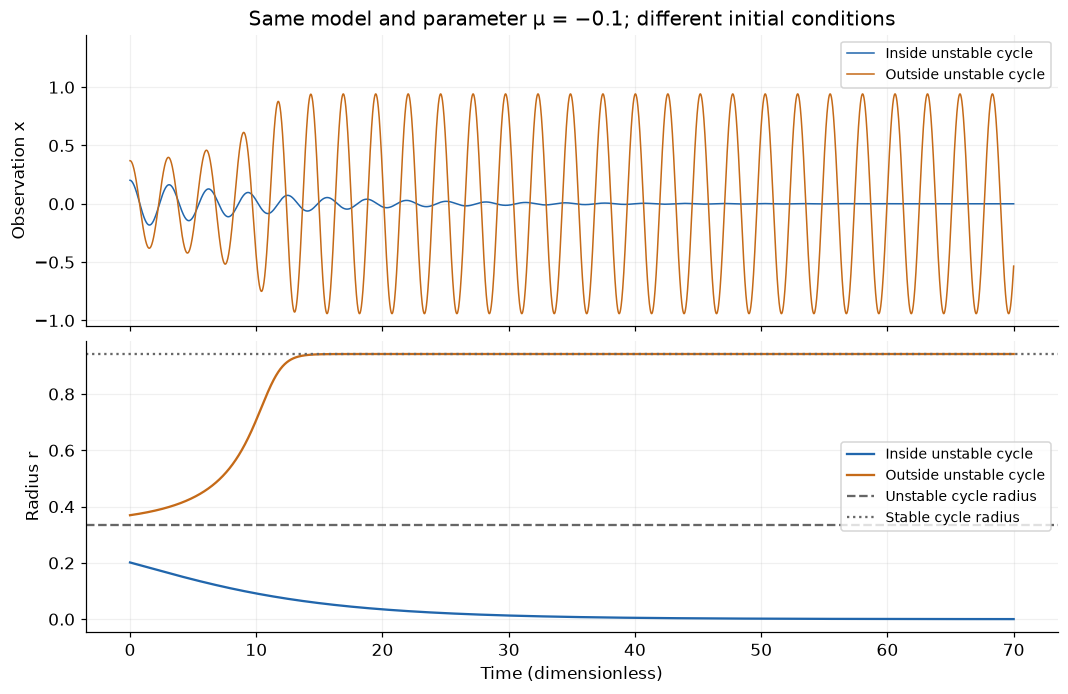

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(10.5, 9), sharex=True, sharey=True,
                         layout='constrained')
portrait_solutions = {}
for ax, (model, mu) in zip(axes.flat,
                          [('super', -0.1), ('super', 0.1), ('sub', -0.1), ('sub', 0.1)]):
    if model == 'sub' and mu < 0:
        initials = [0.6*r_inner, 1.1*r_inner, 1.15]
    else:
        initials = [0.08, 0.55, 1.15]
    gx, gy = np.meshgrid(np.linspace(-1.2, 1.2, 13), np.linspace(-1.2, 1.2, 13))
    gain = radial_gain(gx*gx+gy*gy, mu, model)
    omega = angular_speed(gx*gx+gy*gy, model)
    vx, vy = gain*gx-omega*gy, omega*gx+gain*gy
    norm = np.hypot(vx, vy)
    ax.quiver(gx, gy, vx/np.maximum(norm, 1e-15), vy/np.maximum(norm, 1e-15),
               color='0.8', scale=25, width=0.003)
    for k, r0 in enumerate(initials):
        sol = integrate(mu, model, [r0, 0], 70.)
        portrait_solutions[(model, mu, k)] = sol
        times = np.linspace(0, 70, 4001)
        xy = sol.sol(times)
        color = [COLORS['stable'], COLORS['unstable'], COLORS['neutral']][k]
        ax.plot(*xy, color=color, linewidth=1, alpha=0.85)
        ax.plot(r0, 0, 'o', color=color, markersize=4)
    angle = np.linspace(0, 2*np.pi, 501)
    for radius, stability in cycle_radii(mu, model):
        ax.plot(radius*np.cos(angle), radius*np.sin(angle),
                 '--' if stability == 'unstable' else ':',
                 color='0.15', linewidth=1.5)
    ax.set(title=f'{model.capitalize()}: μ = {mu:g}', xlim=(-1.3, 1.3),
           ylim=(-1.3, 1.3), aspect='equal', xlabel='x (dimensionless)', ylabel='y (dimensionless)')
show_and_save(fig, '02_phase_portraits')

fig, axes = plt.subplots(2, 1, figsize=(9.6, 6.2), sharex=True, layout='constrained')
wave_times = np.linspace(0, 70, 5001)
for k, label, color in [(0, 'Inside unstable cycle', COLORS['stable']),
                        (1, 'Outside unstable cycle', COLORS['unstable'])]:
    xy = portrait_solutions[('sub', -0.1, k)].sol(wave_times)
    axes[0].plot(wave_times, xy[0], color=color, linewidth=1, label=label)
    axes[1].plot(wave_times, np.hypot(*xy), color=color, label=label)
axes[0].set(title='Same model and parameter μ = −0.1; different initial conditions',
            ylabel='Observation x')
axes[1].axhline(r_inner, color='0.4', linestyle='--', label='Unstable cycle radius')
axes[1].axhline(r_outer, color='0.4', linestyle=':', label='Stable cycle radius')
axes[1].set(xlabel='Time (dimensionless)', ylabel='Radius r')
axes[0].set_ylim(-1.05, 1.45)
axes[0].legend(fontsize=9, loc='upper right')
axes[1].legend(fontsize=9, loc='center right')
show_and_save(fig, '03_bistable_waveforms')

**Interpretation:** the same negative $\mu$ supports damped rotations or sustained oscillations in the subcritical extension, depending on initial radius. In the supercritical model, negative $\mu$ produces decay; positive $\mu$ produces a stable cycle. There is no deterministic chaotic attractor in these autonomous radial systems.

### 3. Independent radial benchmarks
For the supercritical model with $q_0=r_0^2$ and $\mu\ne0$,
$$q(t)=\frac{q_0e^{2\mu t}}{1+(q_0/\mu)(e^{2\mu t}-1)}.$$
At $\mu=0$, $q(t)=q_0/(1+2q_0t)$. These give an exact transient-amplitude benchmark. We compare Cartesian integration to the exact radius, and separately compare a subcritical Cartesian trajectory to an independently integrated scalar radial ODE. Agreement checks coordinate implementation, not empirical neuronal validity.

In [7]:
def super_exact_radius(times, mu, r0):
    q0 = r0*r0
    if mu == 0:
        return r0/np.sqrt(1+2*q0*np.asarray(times))
    e = np.exp(2*mu*np.asarray(times))
    return np.sqrt(q0*e/(1+(q0/mu)*np.expm1(2*mu*np.asarray(times))))

benchmark_times = np.linspace(0, 60, 2001)
radial_errors = []
for mu in [-0.1, 0., 0.2]:
    r0 = 0.4
    sol = integrate(mu, 'super', [r0, 0], 60, rtol=1e-11, atol=1e-13)
    observed_r = np.hypot(*sol.sol(benchmark_times))
    err = np.max(np.abs(observed_r-super_exact_radius(benchmark_times, mu, r0)))
    radial_errors.append(float(err))
    print(f'Supercritical μ={mu:g}: max absolute radius error {err:.3e}')
radial_sol = solve_ivp(lambda t, r: [r[0]*radial_gain(r[0]**2, -0.1, 'sub')],
                       (0, 70), [1.1*r_inner], method='DOP853',
                       rtol=1e-11, atol=1e-13, dense_output=True, max_step=0.2)
assert radial_sol.success
radial_vs_cartesian = float(np.max(np.abs(radial_sol.sol(wave_times)[0]
    - np.hypot(*portrait_solutions[('sub', -0.1, 1)].sol(wave_times)))))
print(f'Subcritical scalar radial versus Cartesian error: {radial_vs_cartesian:.3e}')

Supercritical μ=-0.1: max absolute radius error 2.562e-12
Supercritical μ=0: max absolute radius error 3.917e-12
Supercritical μ=0.2: max absolute radius error 4.773e-12
Subcritical scalar radial versus Cartesian error: 5.835e-10


### 4. Cycle periods and finite-frequency onset
For a known cycle radius $r_*$,
$$T=\frac{2\pi}{\Omega(r_*^2)},\qquad f=\frac{\Omega(r_*^2)}{2\pi}.$$
We initialize exactly on the analytically known stable cycle, integrate $6.2T$, exclude the initial event at $t=0$, and estimate period from subsequent positive $y=0,x>0$ crossings. This tests an established orbit rather than estimating the decay time of arbitrary transients. The maximum step of $0.15$ is much shorter than the roughly $2.5$–$3.5$ periods in these examples; a smaller-step method comparison is included below.

The supercritical **cycle-frequency limit** is nonzero while its amplitude vanishes. It must not automatically be called a biological spike-frequency jump. In the subcritical extension, the stable outer cycle at $\mu\to0$ has $r\to\sqrt\beta$ and $f\to(\omega_0+c_3\beta)/(2\pi)$, distinct from the frequency of the vanishing unstable cycle, which tends to $\omega_0/(2\pi)$. A stable finite-amplitude orbit is outside what the local Hopf eigenvalues alone predict.

,model,mu,radius_exact,frequency_numeric,relative_period_error
0,super,0.0100000,0.1000000,0.3175141,4.0061288e-12
4,super,0.0547723,0.2340347,0.3139512,3.3630876e-12
8,super,0.3000000,0.5477226,0.2944366,1.6617818e-12
9,sub,-0.2400000,0.7745967,0.3660564,1.6203483e-11
11,sub,-0.1000000,0.9419651,0.3889188,2.9214409e-12
12,sub,0.0000000,1.0000000,0.3978874,2.2217339e-11
14,sub,0.2000000,1.0820445,0.4114808,1.9646174e-11


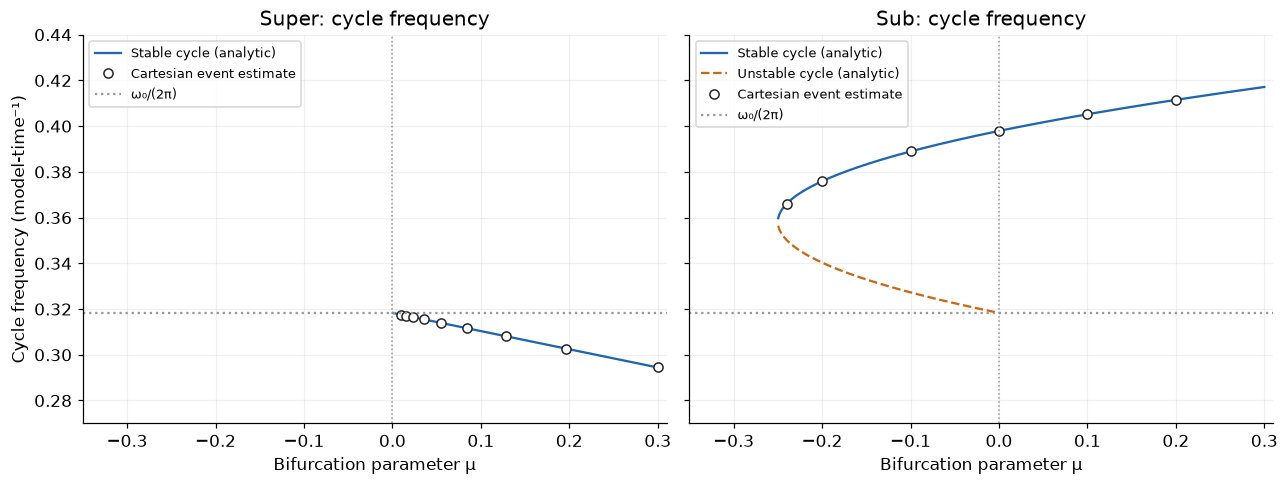

In [9]:
def established_cycle_benchmark(mu, model, *, rtol=1e-9, method='DOP853', max_step=0.15):
    radius = next(r for r, s in cycle_radii(mu, model) if s == 'stable')
    omega = angular_speed(radius**2, model)
    if omega <= 0:
        raise ValueError('This event benchmark assumes positive angular speed.')
    period = 2*np.pi/omega
    sol = integrate(mu, model, [radius, 0], 6.2*period, method=method,
                    rtol=rtol, atol=rtol/100, max_step=max_step)
    events = sol.t_events[0]
    event_xy = sol.y_events[0]
    events = events[(events > 1e-7) & (event_xy[:, 0] > 0)]
    if len(events) < 4:
        raise RuntimeError('Insufficient positive-axis cycles detected.')
    mean_period = float(np.diff(events).mean())
    expected_events = period*np.arange(1, len(events)+1)
    sampled_r = np.hypot(*sol.sol(np.linspace(0, 6.2*period, 1501)))
    return {'model': model, 'mu': mu, 'radius_exact': radius,
            'frequency_exact': 1/period, 'frequency_numeric': 1/mean_period,
            'relative_period_error': abs(mean_period/period-1),
            'max_radius_error': float(np.max(abs(sampled_r-radius))),
            'max_event_time_error': float(np.max(abs(events-expected_events))),
            'nfev': sol.nfev}

period_rows = [established_cycle_benchmark(float(mu), 'super')
               for mu in np.geomspace(0.01, 0.3, 9)]
period_rows += [established_cycle_benchmark(float(mu), 'sub')
                for mu in [-0.24, -0.2, -0.1, 0., 0.1, 0.2]]
period_table = pd.DataFrame(period_rows)
period_table.to_csv(OUTPUT_DIR/'cycle_periods.csv', index=False)
display(period_table.iloc[[0, 4, 8, 9, 11, 12, 14]][
    ['model', 'mu', 'radius_exact', 'frequency_numeric', 'relative_period_error']])

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.3), sharey=True, layout='constrained')
for ax, model in zip(axes, ['super', 'sub']):
    for stability, style in [('stable', '-'), ('unstable', '--')]:
        points = []
        for mu in mu_grid:
            rr = [r for r, s in cycle_radii(mu, model) if s == stability]
            points.append(angular_speed(rr[0]**2, model)/(2*np.pi) if rr else np.nan)
        if np.isfinite(points).any():
            ax.plot(mu_grid, points, style, color=COLORS[stability],
                     label=f'{stability.capitalize()} cycle (analytic)')
    subset = period_table[period_table.model == model]
    ax.plot(subset.mu, subset.frequency_numeric, 'o', mfc='white',
             mec='0.15', label='Cartesian event estimate')
    ax.axhline(OMEGA0/(2*np.pi), color='0.6', linestyle=':', label='ω₀/(2π)')
    ax.axvline(0, color='0.6', linestyle=':', linewidth=1)
    ax.set(xlabel='Bifurcation parameter μ', title=f'{model.capitalize()}: cycle frequency',
           xlim=(-0.35, 0.31), ylim=(0.27, 0.44))
    ax.legend(fontsize=8.5, loc='upper left')
axes[0].set_ylabel('Cycle frequency (model-time⁻¹)')
show_and_save(fig, '04_cycle_frequencies')

### 5. Basin boundary and pulse-induced switching
At $\mu=-0.1$, the exact unforced basin boundary is the unstable circle $r=r_-$. Initial conditions with $r<r_-$ converge to rest; those with $r>r_-$ converge to the stable outer cycle. A point exactly on the boundary stays on the unstable cycle in exact arithmetic and is not a robust classification test.

We test initial radii on both sides, avoiding a 10% neighborhood of the boundary to limit long escape transients. Finite-time endpoints are checked against their exact attracting radii. Then, starting at the origin, we apply square pulses in the $x$ direction for $D=0.25$ at $t=5$, using amplitudes $A=0.8$ and $A=2.0$. After the pulse, the endpoint radius determines the unforced basin; the observation continues to $t=160$ to resolve slow decay toward rest. The input is an additive force, not a radial kick or parameter shift.

An instantaneous displacement from exact rest would have exact threshold magnitude $J_{crit}=r_-$. For a finite pulse, $AD$ is not generally the endpoint radius: rotation and radial dynamics act during the pulse. We numerically locate the finite-pulse amplitude threshold instead of substituting the impulse formula.

,amplitude,duration,pulse_integral_A_D,radius_at_pulse_end,radius_at_t160,outcome
0,0.8,0.25,0.2,0.1959192,4.7157278e-08,Returns to rest
1,2.0,0.25,0.5,0.4947890,9.4196515e-01,Switches to cycle


Unstable radius / ideal impulse threshold: 0.335710687
Finite pulse threshold amplitude (D=0.25): 1.365237860
Threshold signed input integral A*D: 0.341309465


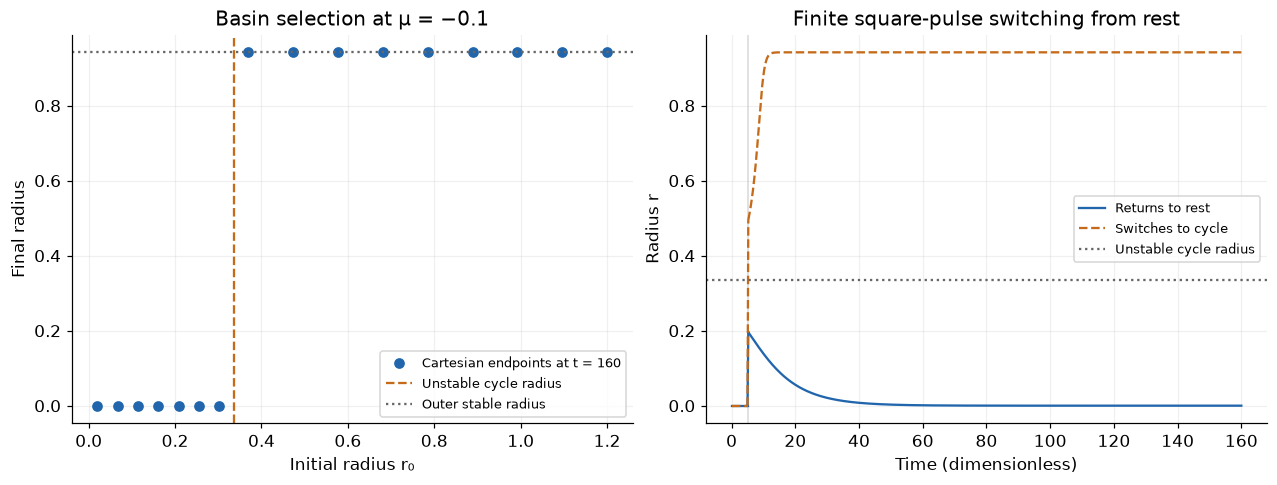

In [24]:
basin_initials = np.r_[np.linspace(0.02, 0.9*r_inner, 7),
                        np.linspace(1.1*r_inner, 1.2, 9)]
basin_rows = []
for r0 in basin_initials:
    sol = integrate(-0.1, 'sub', [r0, 0], 160)
    final_r = float(np.hypot(*sol.y[:, -1]))
    expected = 0. if r0 < r_inner else r_outer
    basin_rows.append({'initial_radius': r0, 'final_radius': final_r,
                       'expected_attractor_radius': expected,
                       'absolute_endpoint_error': abs(final_r-expected)})
basin_table = pd.DataFrame(basin_rows)
basin_table.to_csv(OUTPUT_DIR/'basin_scan.csv', index=False)

PULSE_ON, PULSE_DURATION, PULSE_STOP = 5., 0.25, 160.
pulse_runs, pulse_rows = {}, []
for amplitude, label in [(0.8, 'Returns to rest'), (2., 'Switches to cycle')]:
    pre = integrate(-0.1, 'sub', [0, 0], PULSE_ON)
    active = integrate(-0.1, 'sub', pre.y[:, -1], PULSE_DURATION,
                       start=PULSE_ON, force=(amplitude, 0))
    post = integrate(-0.1, 'sub', active.y[:, -1],
                     PULSE_STOP-PULSE_ON-PULSE_DURATION,
                     start=PULSE_ON+PULSE_DURATION)
    pulse_runs[label] = (pre, active, post)
    pulse_rows.append({'amplitude': amplitude, 'duration': PULSE_DURATION,
                       'pulse_integral_A_D': amplitude*PULSE_DURATION,
                       'radius_at_pulse_end': float(np.hypot(*active.y[:, -1])),
                       'radius_at_t160': float(np.hypot(*post.y[:, -1])),
                       'outcome': label})
pulse_table = pd.DataFrame(pulse_rows)
pulse_table.to_csv(OUTPUT_DIR/'pulse_switching.csv', index=False)
display(pulse_table)

def pulse_endpoint_margin(amplitude):
    sol = integrate(-0.1, 'sub', [0, 0], PULSE_DURATION,
                     force=(amplitude, 0), rtol=1e-11, atol=1e-13, max_step=0.025)
    return float(np.hypot(*sol.y[:, -1])-r_inner)

amplitude_threshold = brentq(pulse_endpoint_margin, 0.8, 2.0, xtol=1e-11, rtol=1e-12)
print(f'Unstable radius / ideal impulse threshold: {r_inner:.9f}')
print(f'Finite pulse threshold amplitude (D=0.25): {amplitude_threshold:.9f}')
print(f'Threshold signed input integral A*D: {amplitude_threshold*PULSE_DURATION:.9f}')

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.3), layout='constrained')
axes[0].plot(basin_table.initial_radius, basin_table.final_radius, 'o',
             color=COLORS['stable'], label='Cartesian endpoints at t = 160')
axes[0].axvline(r_inner, color=COLORS['unstable'], linestyle='--', label='Unstable cycle radius')
axes[0].axhline(r_outer, color='0.4', linestyle=':', label='Outer stable radius')
axes[0].set(xlabel='Initial radius r₀', ylabel='Final radius', title='Basin selection at μ = −0.1')
axes[0].legend(fontsize=8.5, loc='lower right')
for (label, solutions), style, color in zip(pulse_runs.items(), ['-', '--'],
                                            [COLORS['stable'], COLORS['unstable']]):
    for k, sol in enumerate(solutions):
        tt = np.linspace(sol.t[0], sol.t[-1], 1001)
        rr = np.hypot(*sol.sol(tt))
        axes[1].plot(tt, rr, style, color=color, label=label if k == 0 else None)
axes[1].axhline(r_inner, color='0.4', linestyle=':', label='Unstable cycle radius')
axes[1].axvspan(PULSE_ON, PULSE_ON+PULSE_DURATION, color='0.75', alpha=0.6)
axes[1].set(xlabel='Time (dimensionless)', ylabel='Radius r', title='Finite square-pulse switching from rest')
axes[1].legend(fontsize=8.5, loc='center right')
show_and_save(fig, '05_basins_and_pulse_switching')

**Interpretation:** the two inputs select different attractors after forcing stops. Switching to a sustained cycle is a bistable state change, not the isolated excursion and automatic return seen for the negative-drive theta neuron. Suppressing an existing cycle would require a perturbation that moves the state inside the unstable circle; its effect depends on direction, phase, and duration.

### 6. Hysteresis with an explicit seeded-relaxation protocol
For the quintic extension, ideal stable-branch following loses rest at $\mu=0$ on an upward sweep and loses the outer cycle at $\mu_F=-0.25$ on a downward sweep. The analytic bistability width is $0.25$. A finite numerical protocol need not switch exactly at either boundary.

**Important invariant:** $z=0$ stays exactly zero for all $\mu$ without forcing. Carrying exact rest into unstable parameter values will not spontaneously create an oscillation. To make the experiment reproducible, each step starts with radius $\max(r_{previous},0.01)$; this explicitly imposes a radial seed, not hidden noise. At every negative bistable grid point, that seed is below the unstable cycle.

Protocol: $\mu=-0.35,-0.34,\ldots,0.15$ upward, then the same grid downward; fixed dwell time 400 per parameter, repeated with dwell 800. Only the autonomous radial ODE is needed. We integrate $w=\log r$ with
$$\dot w=\mu+\beta e^{2w}-e^{4w}$$
to preserve positive radius without numerical sign changes or underflow in the state variable. The downward sweep starts from the final upward state. We classify $r_{end}>0.3$ as the large-cycle branch **for this protocol** and report grid brackets, not exact bifurcation estimates. Those brackets depend on seed, dwell, grid, and classification rule; this is seeded relaxation continuation, not a continuous-rate sweep.

,dwell,up_bracket_low,up_bracket_high,down_bracket_low,down_bracket_high
0,400.0,0.0,0.01,-0.26,-0.25
1,800.0,0.0,0.01,-0.26,-0.25


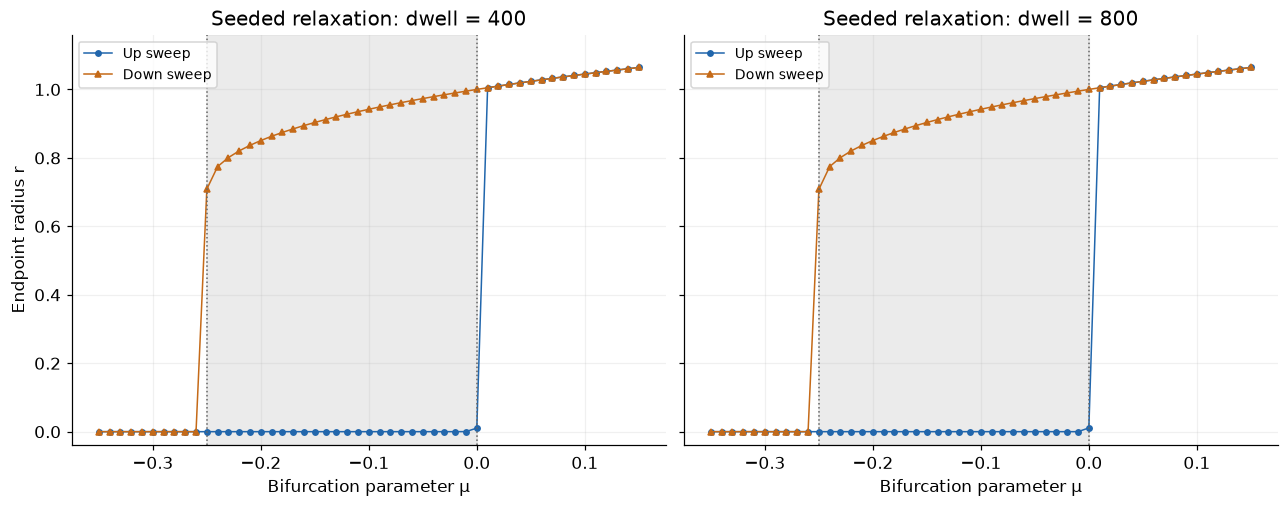

In [22]:
CONTINUATION_SEED = 0.01
CLASSIFICATION_RADIUS = 0.3
continuation_mu = np.round(np.linspace(-0.35, 0.15, 51), 2)

def continuation(dwell):
    rows = []
    previous_r = CONTINUATION_SEED
    for direction, grid in [('up', continuation_mu), ('down', continuation_mu[::-1])]:
        for mu in grid:
            initial_r = max(previous_r, CONTINUATION_SEED)
            def log_rhs(t, w):
                q = np.exp(2*w[0])
                return [mu+BETA*q-q*q]
            sol = solve_ivp(log_rhs, (0, dwell), [np.log(initial_r)],
                            method='DOP853', rtol=1e-9, atol=1e-11, max_step=3)
            if not sol.success:
                raise RuntimeError(sol.message)
            previous_r = float(np.exp(sol.y[0, -1]))
            rows.append({'dwell': dwell, 'direction': direction, 'mu': mu,
                         'initial_radius': initial_r, 'final_radius': previous_r,
                         'large_cycle': previous_r > CLASSIFICATION_RADIUS})
    return pd.DataFrame(rows)

continuation_table = pd.concat([continuation(400.), continuation(800.)], ignore_index=True)
continuation_table.to_csv(OUTPUT_DIR/'seeded_continuation.csv', index=False)
switch_rows = []
for dwell in [400., 800.]:
    up = continuation_table[(continuation_table.dwell == dwell) &
                             (continuation_table.direction == 'up')]
    down = continuation_table[(continuation_table.dwell == dwell) &
                               (continuation_table.direction == 'down')]
    up_mu = up.mu.to_numpy(); up_state = up.large_cycle.to_numpy()
    down_mu = down.mu.to_numpy(); down_state = down.large_cycle.to_numpy()
    up_indices = np.flatnonzero(np.diff(up_state.astype(int)) == 1)
    down_indices = np.flatnonzero(np.diff(down_state.astype(int)) == -1)
    if len(up_indices) != 1 or len(down_indices) != 1:
        raise RuntimeError('Expected one upward and one downward switch.')
    k, j = int(up_indices[0]), int(down_indices[0])
    switch_rows.append({'dwell': dwell, 'up_bracket_low': up_mu[k],
                        'up_bracket_high': up_mu[k+1],
                        'down_bracket_low': down_mu[j+1],
                        'down_bracket_high': down_mu[j]})
switch_table = pd.DataFrame(switch_rows)
switch_table.to_csv(OUTPUT_DIR/'switch_brackets.csv', index=False)
display(switch_table)

fig, axes = plt.subplots(1, 2, figsize=(11.6, 4.5), sharey=True, layout='constrained')
for ax, dwell in zip(axes, [400., 800.]):
    for direction, marker, color in [('up', 'o', COLORS['stable']),
                                      ('down', '^', COLORS['unstable'])]:
        part = continuation_table[(continuation_table.dwell == dwell) &
                                   (continuation_table.direction == direction)]
        ax.plot(part.mu, part.final_radius, marker+'-', color=color,
                 markersize=3.5, linewidth=1, label=f'{direction.capitalize()} sweep')
    ax.axvspan(MU_FOLD, 0, color='0.85', alpha=0.5)
    ax.axvline(MU_FOLD, color='0.4', linestyle=':', linewidth=1)
    ax.axvline(0, color='0.4', linestyle=':', linewidth=1)
    ax.set(xlabel='Bifurcation parameter μ', title=f'Seeded relaxation: dwell = {dwell:g}',
            ylim=(-0.04, 1.16))
    ax.legend(fontsize=9, loc='upper left')
axes[0].set_ylabel('Endpoint radius r')
show_and_save(fig, '06_seeded_hysteresis')

**Interpretation:** the same parameter can retain different states depending on sweep direction. Comparing dwell times exposes some protocol sensitivity; agreement of grid brackets is not proof that finite-time transitions equal the mathematical boundaries. The semistable fold requires long relaxation, and rest near Hopf relaxes slowly. The two analytic boundaries are known from the polynomial, not inferred solely from the plotted sweep.

### 7. Solver convergence and radial Floquet stability
At supercritical $\mu=0.2$, RK45 cycle-period errors are compared against the exact frequency as tolerances tighten. A transient from $r_0=0.4$ at the same parameter is checked against the exact radial solution. A DOP853 run with a smaller maximum step is the independent method/step comparison.

To check the nontrivial Floquet multiplier, perturb a stable cycle's initial radius by $\delta=10^{-6}$ and integrate the scalar radial dynamics for one unperturbed period. The finite-difference estimate
$$M_{FD}=\frac{r(T;r_*+\delta)-r(T;r_* -\delta)}{2\delta}$$
is compared with $M=\exp(\lambda_r T)$. The perturbation and absolute tolerance set a subtraction-error floor. This checks radial contraction; the neutral phase multiplier is an analytic consequence of time-translation symmetry, not a claimed numerical computation here.

,method,rtol,relative_period_error,max_transient_radius_error
0,RK45,1.0000000e-03,9.0005144e-04,1.2736218e-03
1,RK45,1.0000000e-05,2.7110528e-06,1.4025531e-06
2,RK45,1.0000000e-07,7.5095722e-09,2.1103728e-08
3,RK45,1.0000000e-09,4.2545412e-11,2.3947122e-10
4,RK45,1.0000000e-11,3.5738079e-13,2.5270341e-12


Small-step DOP853 relative period error: 7.994e-15


,model,mu,radial_exponent,multiplier_exact,multiplier_numeric,absolute_multiplier_error
0,super,0.2,-0.4000000,0.2663948,0.2663948,3.9676262e-11
1,sub,-0.1,-1.3745967,0.0291761,0.0291761,6.1014211e-11


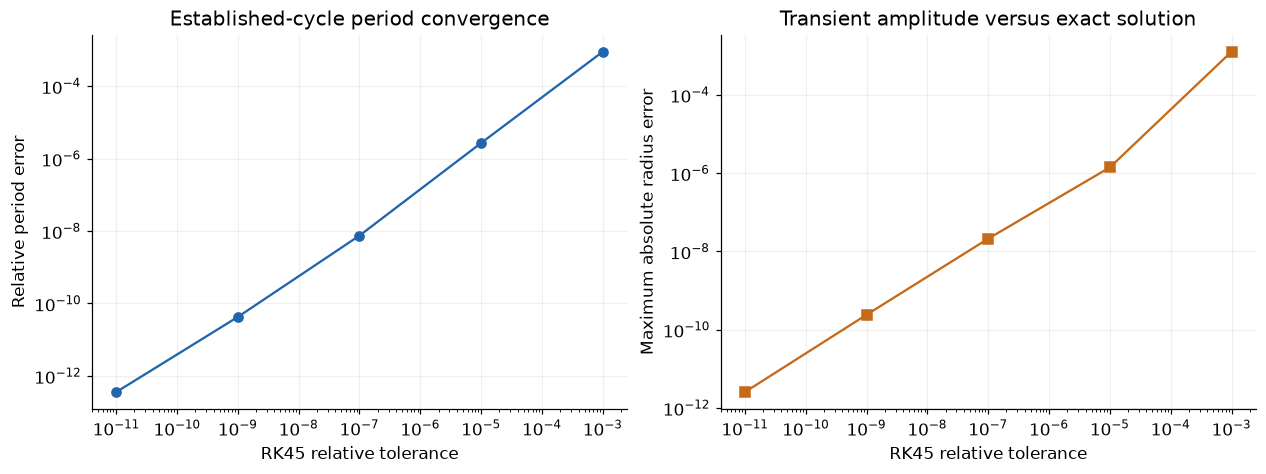

In [18]:
convergence_rows = []
for tol in [1e-3, 1e-5, 1e-7, 1e-9, 1e-11]:
    period_result = established_cycle_benchmark(0.2, 'super',
                                                method='RK45', rtol=tol, max_step=0.5)
    transient = integrate(0.2, 'super', [0.4, 0], 30, method='RK45',
                           rtol=tol, atol=tol/100, max_step=0.5)
    tt = np.linspace(0, 30, 1001)
    r_error = float(np.max(abs(np.hypot(*transient.sol(tt))
                               -super_exact_radius(tt, 0.2, 0.4))))
    convergence_rows.append({'method': 'RK45', 'rtol': tol,
                             'relative_period_error': period_result['relative_period_error'],
                             'max_transient_radius_error': r_error})
method_check = established_cycle_benchmark(0.2, 'super', method='DOP853',
                                            rtol=1e-11, max_step=0.075)
convergence_table = pd.DataFrame(convergence_rows)
convergence_table.to_csv(OUTPUT_DIR/'solver_convergence.csv', index=False)
display(convergence_table)
print('Small-step DOP853 relative period error:', f"{method_check['relative_period_error']:.3e}")

floquet_rows = []
for model, mu in [('super', 0.2), ('sub', -0.1)]:
    radius = next(r for r, s in cycle_radii(mu, model) if s == 'stable')
    period = 2*np.pi/angular_speed(radius*radius, model)
    exponent = radial_exponent(radius, mu, model)
    delta = 1e-6
    endpoints = []
    for r0 in [radius+delta, radius-delta]:
        sol = solve_ivp(lambda t, r: [r[0]*radial_gain(r[0]**2, mu, model)],
                        (0, period), [r0], method='DOP853',
                        rtol=1e-12, atol=1e-14, max_step=0.05)
        assert sol.success
        endpoints.append(sol.y[0, -1])
    numerical_multiplier = float((endpoints[0]-endpoints[1])/(2*delta))
    analytic_multiplier = float(np.exp(exponent*period))
    floquet_rows.append({'model': model, 'mu': mu, 'radial_exponent': exponent,
                         'multiplier_exact': analytic_multiplier,
                         'multiplier_numeric': numerical_multiplier,
                         'absolute_multiplier_error': abs(numerical_multiplier-analytic_multiplier)})
floquet_table = pd.DataFrame(floquet_rows)
floquet_table.to_csv(OUTPUT_DIR/'radial_floquet_checks.csv', index=False)
display(floquet_table)

fig, axes = plt.subplots(1, 2, figsize=(11.4, 4.2), layout='constrained')
axes[0].loglog(convergence_table.rtol, convergence_table.relative_period_error,
                'o-', color=COLORS['stable'])
axes[0].set(xlabel='RK45 relative tolerance', ylabel='Relative period error',
            title='Established-cycle period convergence')
axes[1].loglog(convergence_table.rtol, convergence_table.max_transient_radius_error,
                's-', color=COLORS['unstable'])
axes[1].set(xlabel='RK45 relative tolerance', ylabel='Maximum absolute radius error',
            title='Transient amplitude versus exact solution')
show_and_save(fig, '07_solver_convergence')

## Checks
### Acceptance criteria and limitations of the checks
The following thresholds are declared numerical goals for the chosen experiments. Additional assertions check basin classification, pulse outcomes, grid transition uniqueness, and equilibrium eigenvalues. Fold/Hopf boundaries are analytic; finite dwell endpoints are not substituted for those values. These comparisons establish implementation agreement with a specified mathematical model, not biological validation.

In [26]:
# Numerical Jacobian at the origin: eigenvalues should be μ ± iω₀.
origin_eigen_error = 0.
h = 1e-6
for model in ['super', 'sub']:
    mu = -0.1
    columns = [(np.array(rhs(0, h*axis, mu, model))
                 -np.array(rhs(0, -h*axis, mu, model)))/(2*h)
                for axis in np.eye(2)]
    jac = np.column_stack(columns)
    eig = np.linalg.eigvals(jac)
    origin_eigen_error = max(origin_eigen_error, float(max(abs(eig.real-mu))),
                             float(max(abs(abs(eig.imag)-OMEGA0))))

pulse_threshold_residual = abs(pulse_endpoint_margin(amplitude_threshold))
checks = [
    ('Origin eigenvalue real/imaginary parts', origin_eigen_error, 1e-8),
    ('Exact supercritical radial transients (3 μ)', max(radial_errors), 1e-8),
    ('Subcritical scalar radial versus Cartesian', radial_vs_cartesian, 1e-7),
    ('Established-cycle max relative period error', period_table.relative_period_error.max(), 1e-7),
    ('Established-cycle max absolute radius error', period_table.max_radius_error.max(), 1e-7),
    ('Basin scan max endpoint error', basin_table.absolute_endpoint_error.max(), 1e-6),
    ('Finite pulse threshold endpoint residual', pulse_threshold_residual, 1e-8),
    ('Tight RK45 relative period error', convergence_table.relative_period_error.iloc[-1], 1e-8),
    ('Small-step DOP853 relative period error', method_check['relative_period_error'], 1e-9),
    ('Radial Floquet max absolute multiplier error', floquet_table.absolute_multiplier_error.max(), 1e-7)]
check_table = pd.DataFrame(checks, columns=['check', 'observed_error', 'limit'])
check_table['passed'] = check_table.observed_error < check_table.limit
assert check_table.passed.all(), check_table.loc[~check_table.passed]
assert convergence_table.relative_period_error.iloc[-1] < convergence_table.relative_period_error.iloc[0]
assert pulse_table.radius_at_pulse_end.iloc[0] < r_inner < pulse_table.radius_at_pulse_end.iloc[1]
assert pulse_table.radius_at_t160.iloc[0] < 1e-5
assert abs(pulse_table.radius_at_t160.iloc[1]-r_outer) < 1e-6
assert (floquet_table.multiplier_exact.between(0, 1)).all()
# The explicit seed is below every unstable cycle on the negative bistable grid.
for mu in continuation_mu[(continuation_mu > MU_FOLD) & (continuation_mu < 0)]:
    assert CONTINUATION_SEED < cycle_radii(float(mu), 'sub')[0][0]
# These are properties of this declared protocol, not universal hysteresis tests.
assert np.all(switch_table.up_bracket_low <= 0)
assert np.all(switch_table.up_bracket_high >= 0)
assert np.all(switch_table.down_bracket_low <= MU_FOLD)
assert np.all(switch_table.down_bracket_high >= MU_FOLD)
check_table.to_csv(OUTPUT_DIR/'validation_checks.csv', index=False)
display(check_table)
print('All tabulated accuracy criteria and qualitative assertions passed.')

,check,observed_error,limit,passed
0,Origin eigenvalue real/imaginary parts,1.0000056e-12,1.0000000e-08,True
1,Exact supercritical radial transients (3 μ),4.7727378e-12,1.0000000e-08,True
2,Subcritical scalar radial versus Cartesian,5.8350158e-10,1.0000000e-07,True
3,Established-cycle max relative period error,2.2217339e-11,1.0000000e-07,True
4,Established-cycle max absolute radius error,1.7735406e-09,1.0000000e-07,True
5,Basin scan max endpoint error,8.7329035e-08,1.0000000e-06,True
6,Finite pulse threshold endpoint residual,5.2180482e-15,1.0000000e-08,True
7,Tight RK45 relative period error,3.5738079e-13,1.0000000e-08,True
8,Small-step DOP853 relative period error,7.9936058e-15,1.0000000e-09,True
9,Radial Floquet max absolute multiplier error,6.1014211e-11,1.0000000e-07,True


All tabulated accuracy criteria and qualitative assertions passed.


## Takeaways
The summary below is computed from the executed outputs. The distinction from theta/QIF is structural: Hopf introduces amplitude relaxation and finite-frequency cycle onset, whereas theta/QIF captured a SNIC with frequency tending to zero. The two models do not share a calibrated physical control parameter, so their numerical parameter values should not be compared as equivalent currents.

In [28]:
summary = {
    'versions': VERSIONS, 'time_units': 'dimensionless',
    'omega0': OMEGA0, 'shear': SHEAR, 'beta': BETA,
    'subcritical_fold_mu': MU_FOLD,
    'analytic_bistability_width': -MU_FOLD,
    'bistable_example_mu': MU_BISTABLE,
    'unstable_cycle_radius': float(r_inner),
    'stable_outer_cycle_radius': float(r_outer),
    'supercritical_frequency_limit': OMEGA0/(2*np.pi),
    'subcritical_outer_frequency_at_mu0': (OMEGA0+SHEAR*BETA)/(2*np.pi),
    'max_relative_cycle_period_error': float(period_table.relative_period_error.max()),
    'finite_pulse_duration': PULSE_DURATION,
    'finite_pulse_amplitude_threshold': float(amplitude_threshold),
    'hysteresis_seed': CONTINUATION_SEED,
    'hysteresis_switch_brackets': switch_table.to_dict(orient='records'),
    'accuracy_checks_passed': int(check_table.passed.sum())}
(OUTPUT_DIR/'summary.json').write_text(json.dumps(summary, indent=2)+'\n')
up = switch_table.iloc[0]
display(Markdown(f"""
- **Supercritical onset:** radius tends to zero while cycle frequency tends to **{OMEGA0/(2*np.pi):.6f}** per model-time unit; these small oscillations are not automatically spikes.
- **Subcritical extension:** analytic bistability interval **−0.25 < μ < 0**, width **0.25**.
- **At μ = −0.1:** unstable basin-boundary radius **{r_inner:.6f}**; stable outer radius **{r_outer:.6f}**.
- **Finite pulse:** at duration **0.25**, the computed switching threshold amplitude is **{amplitude_threshold:.6f}** for the specified positive-x pulse from rest.
- **Seeded hysteresis (dwell 400):** upward switch bracket **[{up.up_bracket_low:.2f}, {up.up_bracket_high:.2f}]**; downward bracket **[{up.down_bracket_low:.2f}, {up.down_bracket_high:.2f}]**. The dwell-800 result is tabulated above.
- **Numerical accuracy:** maximum relative period error **{summary['max_relative_cycle_period_error']:.2e}** across **{len(period_table)}** established-cycle benchmarks; all **{len(check_table)}** tabulated criteria passed.
"""))


- **Supercritical onset:** radius tends to zero while cycle frequency tends to **0.318310** per model-time unit; these small oscillations are not automatically spikes.
- **Subcritical extension:** analytic bistability interval **−0.25 < μ < 0**, width **0.25**.
- **At μ = −0.1:** unstable basin-boundary radius **0.335711**; stable outer radius **0.941965**.
- **Finite pulse:** at duration **0.25**, the computed switching threshold amplitude is **1.365238** for the specified positive-x pulse from rest.
- **Seeded hysteresis (dwell 400):** upward switch bracket **[0.00, 0.01]**; downward bracket **[-0.26, -0.25]**. The dwell-800 result is tabulated above.
- **Numerical accuracy:** maximum relative period error **2.22e-11** across **15** established-cycle benchmarks; all **10** tabulated criteria passed.


## Next steps
**Next single-neuron model: FitzHugh–Nagumo.** Add a recovery variable, study nullclines, equilibria and Jacobians, pulse-triggered excursions, slow–fast motion, and parameter-dependent onset. This will distinguish a recovery-based excitable system from the radial amplitude–phase geometry studied here. Hindmarsh–Rose can then add a slow bursting variable before coupled-pair and network studies.

For later networks, declare whether input couples into $x$, $y$, both coordinates, or a reduced phase equation. Coordinate coupling is not automatically a chemical synapse. Near small amplitude or rest, phase-only reduction can fail. The present two-dimensional models have no imposed spike/reset rule or separate refractory state.

### References and provenance
- Gerstner, Kistler, Naud & Paninski (2014), *Neuronal Dynamics*, [§4.4: Type I/II models and Hopf onset](https://neuronaldynamics.epfl.ch/online/Ch4.S4.html). Retrieved 2026-10-26. This supports the distinction between local Hopf oscillations and neuronal firing; the algebraic branch formulas and experiments here follow from the displayed polynomial models.
- Kuznetsov, *Elements of Applied Bifurcation Theory*, 2nd ed., [author's textbook hosted at Imperial College](https://www.ma.imperial.ac.uk/~dturaev/kuznetsov.pdf), chapters on Hopf and generalized Hopf/Bautin bifurcations. The extension is a slice of a quintic amplitude normal-form family; no claim is made to compute a codimension-two unfolding here.
- [SciPy `solve_ivp` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html), for numerical integration and event handling. Installed package versions appear in Setup.

**Limits:** illustrative parameters and normal-form coordinates are not fitted neuronal quantities. The stable outer cycle and its fold may lie outside a biological model's valid local normal-form neighborhood. Rotational symmetry makes the unforced basin boundary circular; real models need not have this symmetry. Pulse thresholds depend on the forcing channel and initial state. The finite dwell/seed protocol is not spontaneous noisy switching, an infinitely slow limit, or a physical sweep-rate experiment. No deterministic chaos, biological refractory period, or network collective behavior is inferred. Project PDFs are not analyzed in this notebook.